In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("crop_dataset.csv")  # change path if needed

# View data
print(df.head())
print(df.columns)


           crop  year       season  state     area  production  fertilizer  \
0      Arecanut  1997  Whole Year   assam  73814.0       56708  7024878.38   
1     Arhar/Tur  1997  Kharif       assam   6637.0        4685   631643.29   
2   Castor seed  1997  Kharif       assam    796.0          22    75755.32   
3      Coconut   1997  Whole Year   assam  19656.0   126905000  1870661.52   
4  Cotton(lint)  1997  Kharif       assam   1739.0         794   165500.63   

   pesticide        yield  avg_temp_c  total_rainfall_mm  \
0   22882.34     0.796087       22.41            1468.92   
1    2057.47     0.710435       22.41            1468.92   
2     246.76     0.238333       22.41            1468.92   
3    6093.36  5238.051739       22.41            1468.92   
4     539.09     0.420909       22.41            1468.92   

   avg_humidity_percent   N   P   K   pH  
0                 70.71  60  18  38  5.8  
1                 70.71  60  18  38  5.8  
2                 70.71  60  18  38  5.8 

In [3]:
df = df.dropna()

In [4]:
df['drought'] = df['total_rainfall_mm'] < df['total_rainfall_mm'].quantile(0.2)
df['heatwave'] = df['avg_temp_c'] > df['avg_temp_c'].quantile(0.8)

In [5]:
df['drought'] = df['drought'].astype(int)
df['heatwave'] = df['heatwave'].astype(int)


In [6]:
df['rainfall_dev'] = df['total_rainfall_mm'] - df['total_rainfall_mm'].mean()
df['temp_dev'] = df['avg_temp_c'] - df['avg_temp_c'].mean()
features = ['total_rainfall_mm', 'avg_temp_c', 'avg_humidity_percent',
            'drought', 'heatwave',
            'rainfall_dev', 'temp_dev']

X = df[features]
y = df['yield']
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Example split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
lr = LinearRegression()
lr.fit(X_train, y_train)


LinearRegression()
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
dt = DecisionTreeRegressor(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
def evaluate(y_test, pred, name):
    print(f"\n{name} Performance:")
    print("R2 Score:", r2_score(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

evaluate(y_test, lr_pred, "Linear Regression")
evaluate(y_test, dt_pred, "Decision Tree")
evaluate(y_test, rf_pred, "Random Forest")

shock_data = X_test.copy()

shock_data['rainfall'] = shock_data['rainfall'] * 0.7
shock_data['rainfall_dev'] = shock_data['rainfall'] - df['rainfall'].mean()
shock_data['drought'] = 1
normal_pred = rf.predict(X_test)
shock_pred = rf.predict(shock_data)
comparison = pd.DataFrame({
    'Normal_Yield': normal_pred,
    'Shock_Yield': shock_pred
})

print(comparison.head())

# Average comparison
print("\nAverage Normal Yield:", np.mean(normal_pred))
print("Average Shock Yield:", np.mean(shock_pred))
plt.figure()
plt.bar(['Normal', 'Drought'], 
        [np.mean(normal_pred), np.mean(shock_pred)])
plt.title("Yield Comparison: Normal vs Drought")
plt.ylabel("Yield")
plt.show()
 



Linear Regression Performance:
R2 Score: 0.009611120995528522
RMSE: 890.8080891079208

Decision Tree Performance:
R2 Score: 0.004611057208949609
RMSE: 893.0539188945962


NameError: name 'rf_pred' is not defined


Linear Regression Performance:
R2 Score: 0.009611120995528522
RMSE: 890.8080891079208

Decision Tree Performance:
R2 Score: 0.004611057208949609
RMSE: 893.0539188945962

Random Forest Performance:
R2 Score: -0.04138700120007344
RMSE: 913.4554067707302

Sample Comparison:
   Normal_Yield  Shock_Yield
0      1.311208     1.339466
1      3.166978   255.954731
2      3.151745     3.394242
3      4.721637    12.592957
4      5.788003     4.629831

Average Normal Yield: 80.5650224946928
Average Shock Yield: 110.8221420838435


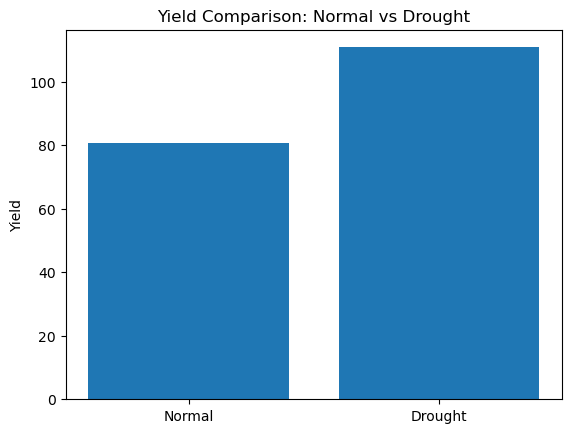

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# -------------------------------
# 📌 CREATE CLIMATE SHOCK FEATURES
# -------------------------------

df['drought'] = (df['total_rainfall_mm'] < df['total_rainfall_mm'].quantile(0.2)).astype(int)
df['heatwave'] = (df['avg_temp_c'] > df['avg_temp_c'].quantile(0.8)).astype(int)

df['rainfall_dev'] = df['total_rainfall_mm'] - df['total_rainfall_mm'].mean()
df['temp_dev'] = df['avg_temp_c'] - df['avg_temp_c'].mean()

# -------------------------------
# 📌 FEATURE SELECTION
# -------------------------------

features = [
    'total_rainfall_mm', 'avg_temp_c', 'avg_humidity_percent',
    'drought', 'heatwave',
    'rainfall_dev', 'temp_dev'
]

X = df[features]
y = df['yield']   # ⚠️ check column name (Yield vs yield)

# -------------------------------
# 📌 TRAIN-TEST SPLIT
# -------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -------------------------------
# 📌 MODELS
# -------------------------------

lr = LinearRegression()
dt = DecisionTreeRegressor(max_depth=5, random_state=42)
rf = RandomForestRegressor(n_estimators=100, random_state=42)

# -------------------------------
# 📌 TRAIN MODELS
# -------------------------------

lr.fit(X_train, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)

# -------------------------------
#  PREDICTIONS
# -------------------------------

lr_pred = lr.predict(X_test)
dt_pred = dt.predict(X_test)
rf_pred = rf.predict(X_test)

# -------------------------------
#  EVALUATION FUNCTION
# -------------------------------

def evaluate(y_test, pred, name):
    print(f"\n{name} Performance:")
    print("R2 Score:", r2_score(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

evaluate(y_test, lr_pred, "Linear Regression")
evaluate(y_test, dt_pred, "Decision Tree")
evaluate(y_test, rf_pred, "Random Forest")

# -------------------------------
# 🌪️ CLIMATE SHOCK SIMULATION (DROUGHT)
# -------------------------------

shock_data = X_test.copy()

# Reduce rainfall by 30%
shock_data['total_rainfall_mm'] = shock_data['total_rainfall_mm'] * 0.7

# Recalculate deviation
shock_data['rainfall_dev'] = shock_data['total_rainfall_mm'] - df['total_rainfall_mm'].mean()

# Force drought condition
shock_data['drought'] = 1

# -------------------------------
#  PREDICT NORMAL VS SHOCK
# -------------------------------

normal_pred = rf.predict(X_test)
shock_pred = rf.predict(shock_data)

# -------------------------------
# 📊 COMPARISON
# -------------------------------

comparison = pd.DataFrame({
    'Normal_Yield': normal_pred,
    'Shock_Yield': shock_pred
})

print("\nSample Comparison:")
print(comparison.head())

print("\nAverage Normal Yield:", np.mean(normal_pred))
print("Average Shock Yield:", np.mean(shock_pred))

# -------------------------------
#  VISUALIZATION
# -------------------------------

plt.figure()
plt.bar(['Normal', 'Drought'],
        [np.mean(normal_pred), np.mean(shock_pred)])

plt.title("Yield Comparison: Normal vs Drought")
plt.ylabel("Yield")
plt.show()


Linear Regression Performance:
R2 Score: 0.009611120995528522
RMSE: 890.8080891079208

Decision Tree Performance:
R2 Score: 0.004611057208949609
RMSE: 893.0539188945962

Random Forest Performance:
R2 Score: -0.04138700120007344
RMSE: 913.4554067707302

Gradient Boosting Performance:
R2 Score: -0.008649059493939681
RMSE: 898.9826673349635

SVR Performance:
R2 Score: -0.007548568691555735
RMSE: 898.4921140816156

Average Normal Yield: 81.64115598010868
Average Shock Yield: 143.1611069470168
Percentage Drop: -75.35409099535173


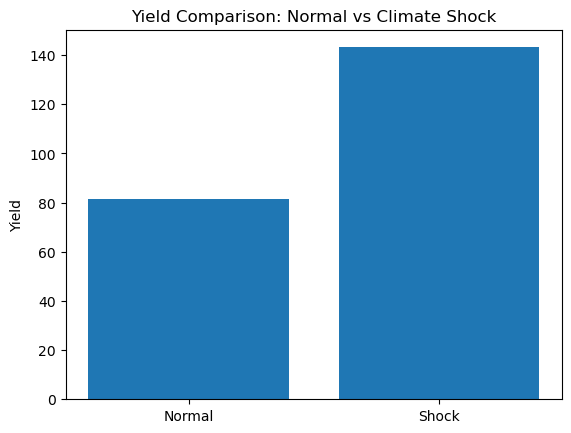

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# -------------------------------
#  CLIMATE SHOCK FEATURES
# -------------------------------

df['drought'] = (df['total_rainfall_mm'] < df['total_rainfall_mm'].quantile(0.2)).astype(int)
df['heatwave'] = (df['avg_temp_c'] > df['avg_temp_c'].quantile(0.8)).astype(int)

df['rainfall_dev'] = df['total_rainfall_mm'] - df['total_rainfall_mm'].mean()
df['temp_dev'] = df['avg_temp_c'] - df['avg_temp_c'].mean()

# -------------------------------
#  FEATURES
# -------------------------------

features = [
    'total_rainfall_mm', 'avg_temp_c', 'avg_humidity_percent',
    'drought', 'heatwave',
    'rainfall_dev', 'temp_dev'
]

X = df[features]
y = df['yield']   # check name

# -------------------------------
#  SPLIT
# -------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -------------------------------
#  SCALING (for SVR)
# -------------------------------

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# -------------------------------
# 📌 MODELS
# -------------------------------

lr = LinearRegression()
dt = DecisionTreeRegressor(max_depth=5, random_state=42)
rf = RandomForestRegressor(n_estimators=100, random_state=42)
gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
svr = SVR(kernel='rbf', C=100, epsilon=0.1)

# -------------------------------
#  TRAIN
# -------------------------------

lr.fit(X_train, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)
gb.fit(X_train, y_train)
svr.fit(X_train_scaled, y_train)

# -------------------------------
# 📌 PREDICT
# -------------------------------

lr_pred = lr.predict(X_test)
dt_pred = dt.predict(X_test)
rf_pred = rf.predict(X_test)
gb_pred = gb.predict(X_test)
svr_pred = svr.predict(X_test_scaled)

# -------------------------------
#  EVALUATE
# -------------------------------

def evaluate(y_test, pred, name):
    print(f"\n{name} Performance:")
    print("R2 Score:", r2_score(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

evaluate(y_test, lr_pred, "Linear Regression")
evaluate(y_test, dt_pred, "Decision Tree")
evaluate(y_test, rf_pred, "Random Forest")
evaluate(y_test, gb_pred, "Gradient Boosting")
evaluate(y_test, svr_pred, "SVR")

# -------------------------------
# CLIMATE SHOCK SIMULATION
# -------------------------------

shock_data = X_test.copy()

# Stronger shock
shock_data['total_rainfall_mm'] *= 0.5
shock_data['avg_temp_c'] += 2

shock_data['rainfall_dev'] = shock_data['total_rainfall_mm'] - df['total_rainfall_mm'].mean()
shock_data['temp_dev'] = shock_data['avg_temp_c'] - df['avg_temp_c'].mean()

shock_data['drought'] = 1
shock_data['heatwave'] = 1

# Scale for SVR
shock_scaled = scaler.transform(shock_data)

# -------------------------------
#  PREDICTIONS
# -------------------------------

normal_pred = gb.predict(X_test)   # use best model later
shock_pred = gb.predict(shock_data)

# -------------------------------
# RESULTS
# -------------------------------

print("\nAverage Normal Yield:", np.mean(normal_pred))
print("Average Shock Yield:", np.mean(shock_pred))

print("Percentage Drop:",
      ((np.mean(normal_pred) - np.mean(shock_pred)) / np.mean(normal_pred)) * 100)

# -------------------------------
# PLOT
# -------------------------------

plt.figure()
plt.bar(['Normal', 'Shock'],
        [np.mean(normal_pred), np.mean(shock_pred)])

plt.title("Yield Comparison: Normal vs Climate Shock")
plt.ylabel("Yield")
plt.show()

Model Performance:
R2 Score: 0.01440720745980062
RMSE: 3.376748236701824

Average Normal Yield: 2.2020215566483197
Average Shock Yield: 1.8519158751734415
Percentage Drop: 15.899284928335188


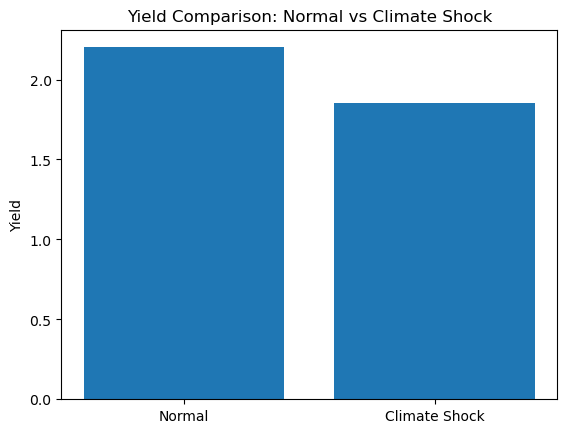

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error

# -------------------------------
#  LOAD DATA
# -------------------------------

df = pd.read_csv("crop_dataset.csv")

# -------------------------------
#  CREATE CLIMATE SHOCK FEATURES
# -------------------------------

df['drought'] = (df['total_rainfall_mm'] < df['total_rainfall_mm'].quantile(0.2)).astype(int)
df['heatwave'] = (df['avg_temp_c'] > df['avg_temp_c'].quantile(0.8)).astype(int)

df['rainfall_dev'] = df['total_rainfall_mm'] - df['total_rainfall_mm'].mean()
df['temp_dev'] = df['avg_temp_c'] - df['avg_temp_c'].mean()

# -------------------------------
#  INTERACTION FEATURES (IMPORTANT)
# -------------------------------

df['temp_rainfall_interaction'] = df['avg_temp_c'] * df['total_rainfall_mm']
df['humidity_temp_interaction'] = df['avg_humidity_percent'] * df['avg_temp_c']

# -------------------------------
#  REMOVE EXTREME NOISE (NOT SHOCKS)
# -------------------------------

df = df[df['yield'] < df['yield'].quantile(0.95)]

# -------------------------------
#  FEATURES
# -------------------------------

features = [
    'total_rainfall_mm', 'avg_temp_c', 'avg_humidity_percent',
    'drought', 'heatwave',
    'rainfall_dev', 'temp_dev',
    'temp_rainfall_interaction', 'humidity_temp_interaction'
]

X = df[features]
y = df['yield']

# -------------------------------
#  TRAIN-TEST SPLIT
# -------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -------------------------------
#  MODEL (BEST CHOICE)
# -------------------------------

model = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# -------------------------------
#  TRAIN
# -------------------------------

model.fit(X_train, y_train)

# -------------------------------
# PREDICT NORMAL
# -------------------------------

normal_pred = model.predict(X_test)

# -------------------------------
#  CLIMATE SHOCK SIMULATION (IMPROVED)
# -------------------------------

shock_data = X_test.copy()

# Strong realistic shock
shock_data['total_rainfall_mm'] *= 0.5
shock_data['avg_temp_c'] += 3
shock_data['avg_humidity_percent'] *= 0.85

# Recalculate derived features
shock_data['rainfall_dev'] = shock_data['total_rainfall_mm'] - df['total_rainfall_mm'].mean()
shock_data['temp_dev'] = shock_data['avg_temp_c'] - df['avg_temp_c'].mean()

shock_data['temp_rainfall_interaction'] = shock_data['avg_temp_c'] * shock_data['total_rainfall_mm']
shock_data['humidity_temp_interaction'] = shock_data['avg_humidity_percent'] * shock_data['avg_temp_c']

# Force extreme condition
shock_data['drought'] = 1
shock_data['heatwave'] = 1

# -------------------------------
#  PREDICT SHOCK
# -------------------------------

shock_pred = model.predict(shock_data)

# -------------------------------
#  EVALUATION
# -------------------------------

print("Model Performance:")
print("R2 Score:", r2_score(y_test, normal_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, normal_pred)))

# -------------------------------
#  RESULTS
# -------------------------------

avg_normal = np.mean(normal_pred)
avg_shock = np.mean(shock_pred)

print("\nAverage Normal Yield:", avg_normal)
print("Average Shock Yield:", avg_shock)

percentage_drop = ((avg_normal - avg_shock) / avg_normal) * 100
print("Percentage Drop:", percentage_drop)

# -------------------------------
#  VISUALIZATION
# -------------------------------

plt.figure()
plt.bar(['Normal', 'Climate Shock'], [avg_normal, avg_shock])
plt.title("Yield Comparison: Normal vs Climate Shock")
plt.ylabel("Yield")
plt.show()

Model Performance:
R2 Score: -0.03343986877476701
RMSE: 5.2850317043172925

Average Normal Yield: 1.6011134347408802
Average Shock Yield: 1.4607846645635743
Percentage Drop: 8.764448984841374


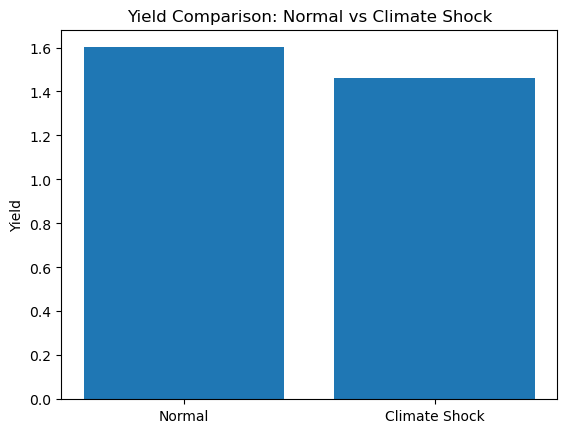

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error

# -------------------------------
#  LOAD DATA
# -------------------------------
df = pd.read_csv("crop_dataset.csv")

# -------------------------------
#  FEATURE ENGINEERING
# -------------------------------

# Climate shock indicators
df['drought'] = (df['total_rainfall_mm'] < df['total_rainfall_mm'].quantile(0.2)).astype(int)
df['heatwave'] = (df['avg_temp_c'] > df['avg_temp_c'].quantile(0.8)).astype(int)

# Deviations
df['rainfall_dev'] = df['total_rainfall_mm'] - df['total_rainfall_mm'].mean()
df['temp_dev'] = df['avg_temp_c'] - df['avg_temp_c'].mean()

# Interaction features (IMPORTANT)
df['temp_rainfall'] = df['avg_temp_c'] * df['total_rainfall_mm']
df['humidity_temp'] = df['avg_humidity_percent'] * df['avg_temp_c']

# Non-linear feature
df['rainfall_sq'] = df['total_rainfall_mm'] ** 2

# -------------------------------
#  REMOVE EXTREME NOISE
# -------------------------------
df = df[df['yield'] < df['yield'].quantile(0.97)]

# -------------------------------
#  FEATURES & TARGET
# -------------------------------
features = [
    'total_rainfall_mm', 'avg_temp_c', 'avg_humidity_percent',
    'rainfall_dev', 'temp_dev',
    'drought', 'heatwave',
    'temp_rainfall', 'humidity_temp',
    'rainfall_sq'
]

X = df[features]

# 🔥 LOG TRANSFORMATION (VERY IMPORTANT)
y = np.log1p(df['yield'])

# -------------------------------
# 📌 TRAIN TEST SPLIT
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -------------------------------
# 📌 MODEL (TUNED)
# -------------------------------
model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

model.fit(X_train, y_train)

# -------------------------------
# 📌 NORMAL PREDICTION
# -------------------------------
normal_pred_log = model.predict(X_test)

# Convert back
normal_pred = np.expm1(normal_pred_log)
y_test_actual = np.expm1(y_test)

# -------------------------------
# 🌪️ CLIMATE SHOCK SIMULATION
# -------------------------------
shock_data = X_test.copy()

shock_data['total_rainfall_mm'] *= 0.4   # strong drought
shock_data['avg_temp_c'] += 3            # heatwave
shock_data['avg_humidity_percent'] *= 0.8

# Recalculate features
shock_data['rainfall_dev'] = shock_data['total_rainfall_mm'] - df['total_rainfall_mm'].mean()
shock_data['temp_dev'] = shock_data['avg_temp_c'] - df['avg_temp_c'].mean()

shock_data['temp_rainfall'] = shock_data['avg_temp_c'] * shock_data['total_rainfall_mm']
shock_data['humidity_temp'] = shock_data['avg_humidity_percent'] * shock_data['avg_temp_c']
shock_data['rainfall_sq'] = shock_data['total_rainfall_mm'] ** 2

shock_data['drought'] = 1
shock_data['heatwave'] = 1

# -------------------------------
# 📌 SHOCK PREDICTION
# -------------------------------
shock_pred_log = model.predict(shock_data)
shock_pred = np.expm1(shock_pred_log)

# -------------------------------
# 📊 EVALUATION
# -------------------------------
print("Model Performance:")
print("R2 Score:", r2_score(y_test_actual, normal_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test_actual, normal_pred)))

# -------------------------------
# 📊 RESULTS
# -------------------------------
avg_normal = np.mean(normal_pred)
avg_shock = np.mean(shock_pred)

print("\nAverage Normal Yield:", avg_normal)
print("Average Shock Yield:", avg_shock)

drop = ((avg_normal - avg_shock) / avg_normal) * 100
print("Percentage Drop:", drop)

# -------------------------------
# 📊 VISUALIZATION
# -------------------------------
plt.figure()
plt.bar(['Normal', 'Climate Shock'], [avg_normal, avg_shock])
plt.title("Yield Comparison: Normal vs Climate Shock")
plt.ylabel("Yield")
plt.show()

In [16]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score

# -------------------------------
# 📌 LOAD DATA
# -------------------------------
df = pd.read_csv("crop_dataset.csv")

# -------------------------------
# 📌 YOUR CROP FEATURES
# -------------------------------
crop_features = {
    'Jute': ['fertilizer','avg_humidity_percent','K'],
    'Sugarcane': ['area','avg_humidity_percent','pH','K'],
    'Garlic': ['fertilizer','avg_humidity_percent','total_rainfall_mm','pH','P'],
    'Arecanut': ['area','total_rainfall_mm','pH'],
    'Wheat': ['area','total_rainfall_mm','N','K']
}

results = []

# -------------------------------
# 🔁 LOOP FOR EACH CROP
# -------------------------------
for crop, features in crop_features.items():

    print(f"\n===== {crop} =====")

    crop_df = df[df['crop'] == crop].copy()

    # Skip if too small
    if len(crop_df) < 20:
        print("Not enough data")
        continue

    # -------------------------------
    # 📌 TARGET (log transform)
    # -------------------------------
    X = crop_df[features]
    y = np.log1p(crop_df['yield'])

    # -------------------------------
    # 📌 TRAIN TEST SPLIT
    # -------------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # -------------------------------
    # 📌 MODEL
    # -------------------------------
    model = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )

    model.fit(X_train, y_train)

    # -------------------------------
    # 📌 NORMAL PREDICTION
    # -------------------------------
    normal_pred = np.expm1(model.predict(X_test))
    y_test_actual = np.expm1(y_test)

    r2 = r2_score(y_test_actual, normal_pred)

    # -------------------------------
    # 🌪️ CLIMATE SHOCK SIMULATION
    # -------------------------------
    # -------------------------------
# 🌪️ CLIMATE SHOCK SIMULATION (FIXED)
# -------------------------------
    shock_data = X_test.copy()

# Apply shock ONLY to existing features
    if 'total_rainfall_mm' in features:
        shock_data['total_rainfall_mm'] *= 0.5

    if 'avg_humidity_percent' in features:
        shock_data['avg_humidity_percent'] *= 0.85

# ❌ REMOVE avg_temp_c completely (not in your feature list)

    # -------------------------------
    # 📌 SHOCK PREDICTION
    # -------------------------------
    shock_pred = np.expm1(model.predict(shock_data))

    # -------------------------------
    # 📊 RESULTS
    # -------------------------------
    avg_normal = np.mean(normal_pred)
    avg_shock = np.mean(shock_pred)

    drop = ((avg_normal - avg_shock) / avg_normal) * 100

    print("R2:", r2)
    print("Normal Yield:", avg_normal)
    print("Shock Yield:", avg_shock)
    print("% Drop:", drop)

    results.append([crop, r2, avg_normal, avg_shock, drop])

# -------------------------------
# 📊 FINAL TABLE
# -------------------------------
results_df = pd.DataFrame(results, columns=[
    'Crop', 'R2', 'Normal_Yield', 'Shock_Yield', 'Percent_Drop'
])

print("\n\nFINAL RESULTS:")
print(results_df)



===== Jute =====
R2: 0.6960706660690297
Normal Yield: 8.169347490112676
Shock Yield: 6.662057863455047
% Drop: 18.45055101991799

===== Sugarcane =====
R2: 0.8420394789880248
Normal Yield: 47.2999407993664
Shock Yield: 35.01567868157468
% Drop: 25.97098835683167

===== Garlic =====
R2: 0.7998491958753533
Normal Yield: 4.677392695536199
Shock Yield: 3.8041208884223305
% Drop: 18.670055391057122

===== Arecanut =====
R2: 0.7976788930134299
Normal Yield: 1.9776732473878682
Shock Yield: 1.7194254813553032
% Drop: 13.058161472005622

===== Wheat =====
R2: 0.835250033440194
Normal Yield: 1.8720571816180909
Shock Yield: 1.7830318141596904
% Drop: 4.755483343807504


FINAL RESULTS:
        Crop        R2  Normal_Yield  Shock_Yield  Percent_Drop
0       Jute  0.696071      8.169347     6.662058     18.450551
1  Sugarcane  0.842039     47.299941    35.015679     25.970988
2     Garlic  0.799849      4.677393     3.804121     18.670055
3   Arecanut  0.797679      1.977673     1.719425     13.058

In [17]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

rf_pred = np.expm1(rf.predict(X_test))

print("RF R2:", r2_score(y_test_actual, rf_pred))

RF R2: 0.8536279225914939


In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# -------------------------------
# 📌 LOAD DATA
# -------------------------------
df = pd.read_csv("crop_dataset.csv")

# -------------------------------
# 📌 CROP FEATURES
# -------------------------------
crop_features = {
    'Jute': ['fertilizer','avg_humidity_percent','K'],
    'Sugarcane': ['area','avg_humidity_percent','pH','K'],
    'Garlic': ['fertilizer','avg_humidity_percent','total_rainfall_mm','pH','P'],
    'Arecanut': ['area','total_rainfall_mm','pH'],
    'Wheat': ['area','total_rainfall_mm','N','K']
}

results = []

# -------------------------------
# 🔁 LOOP FOR EACH CROP
# -------------------------------
for crop, features in crop_features.items():

    print(f"\n===== {crop} =====")

    crop_df = df[df['crop'] == crop].copy()

    if len(crop_df) < 20:
        print("Not enough data")
        continue

    X = crop_df[features]
    y = np.log1p(crop_df['yield'])   # log transform

    # -------------------------------
    # 📌 TRAIN TEST SPLIT
    # -------------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # -------------------------------
    # 📌 MODEL (Random Forest)
    # -------------------------------
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=3,
        random_state=42
    )

    model.fit(X_train, y_train)

    # -------------------------------
    # 📌 NORMAL PREDICTION
    # -------------------------------
    normal_pred = np.expm1(model.predict(X_test))
    y_test_actual = np.expm1(y_test)

    r2 = r2_score(y_test_actual, normal_pred)

    # -------------------------------
    # 🌪️ CLIMATE SHOCK SIMULATION
    # -------------------------------
    shock_data = X_test.copy()

    if 'total_rainfall_mm' in features:
        shock_data['total_rainfall_mm'] *= 0.5   # drought

    if 'avg_humidity_percent' in features:
        shock_data['avg_humidity_percent'] *= 0.85   # dry air

    # -------------------------------
    # 📌 SHOCK PREDICTION
    # -------------------------------
    shock_pred = np.expm1(model.predict(shock_data))

    # -------------------------------
    # 📊 RESULTS
    # -------------------------------
    avg_normal = np.mean(normal_pred)
    avg_shock = np.mean(shock_pred)

    drop = ((avg_normal - avg_shock) / avg_normal) * 100

    print("R2:", r2)
    print("Normal Yield:", avg_normal)
    print("Shock Yield:", avg_shock)
    print("% Drop:", drop)

    results.append([crop, r2, avg_normal, avg_shock, drop])

# -------------------------------
# 📊 FINAL TABLE
# -------------------------------
results_df = pd.DataFrame(results, columns=[
    'Crop', 'R2', 'Normal_Yield', 'Shock_Yield', 'Percent_Drop'
])

print("\n\nFINAL RESULTS:")
print(results_df)


===== Jute =====
R2: 0.7371704783572268
Normal Yield: 7.895782298343252
Shock Yield: 6.215793396189021
% Drop: 21.27704182658048

===== Sugarcane =====
R2: 0.8656590655492034
Normal Yield: 47.12990919900193
Shock Yield: 38.643378637529224
% Drop: 18.00667708829879

===== Garlic =====
R2: 0.7455792712061324
Normal Yield: 4.445692922820761
Shock Yield: 3.6357139698125263
% Drop: 18.21940847174638

===== Arecanut =====
R2: 0.8017197489613517
Normal Yield: 1.9341613676390517
Shock Yield: 1.9147163868523456
% Drop: 1.0053442857480785

===== Wheat =====
R2: 0.8642696449674783
Normal Yield: 1.8702672143674444
Shock Yield: 1.7849848137972915
% Drop: 4.559904590906109


FINAL RESULTS:
        Crop        R2  Normal_Yield  Shock_Yield  Percent_Drop
0       Jute  0.737170      7.895782     6.215793     21.277042
1  Sugarcane  0.865659     47.129909    38.643379     18.006677
2     Garlic  0.745579      4.445693     3.635714     18.219408
3   Arecanut  0.801720      1.934161     1.914716      1.0

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# -------------------------------
# 📌 LOAD DATA
# -------------------------------
df = pd.read_csv("crop_dataset.csv")

# -------------------------------
# 📌 CROP FEATURES
# -------------------------------
crop_features = {
    'Jute': ['fertilizer','avg_humidity_percent','K'],
    'Sugarcane': ['area','avg_humidity_percent','pH','K'],
    'Garlic': ['fertilizer','avg_humidity_percent','total_rainfall_mm','pH','P'],
    'Arecanut': ['area','total_rainfall_mm','pH'],
    'Wheat': ['area','total_rainfall_mm','N','K']
}

results = []

# -------------------------------
# 🔁 LOOP THROUGH CROPS
# -------------------------------
for crop, features in crop_features.items():

    print(f"\n===== {crop} =====")

    crop_df = df[df['crop'] == crop].copy()

    if len(crop_df) < 20:
        print("Not enough data")
        continue

    # -------------------------------
    # 📌 FEATURES & TARGET
    # -------------------------------
    X = crop_df[features]
    y = np.log1p(crop_df['yield'])   # log transform

    # -------------------------------
    # 📌 TRAIN-TEST SPLIT
    # -------------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # -------------------------------
    # 🌲 RANDOM FOREST MODEL
    # -------------------------------
    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features='sqrt',
        random_state=42
    )

    model.fit(X_train, y_train)

    # -------------------------------
    # 📌 NORMAL PREDICTION
    # -------------------------------
    normal_pred = np.expm1(model.predict(X_test))
    y_test_actual = np.expm1(y_test)

    r2 = r2_score(y_test_actual, normal_pred)

    # -------------------------------
    # 🌪️ CLIMATE SHOCK SIMULATION
    # -------------------------------
    shock_data = X_test.copy()

    if 'total_rainfall_mm' in features:
        shock_data['total_rainfall_mm'] *= 0.5   # drought

    if 'avg_humidity_percent' in features:
        shock_data['avg_humidity_percent'] *= 0.85   # dry condition

    # -------------------------------
    # 📌 SHOCK PREDICTION
    # -------------------------------
    shock_pred = np.expm1(model.predict(shock_data))

    # -------------------------------
    # 📊 RESULTS
    # -------------------------------
    avg_normal = np.mean(normal_pred)
    avg_shock = np.mean(shock_pred)

    drop = ((avg_normal - avg_shock) / avg_normal) * 100

    print("R2:", r2)
    print("Normal Yield:", avg_normal)
    print("Shock Yield:", avg_shock)
    print("% Drop:", drop)

    results.append([crop, r2, avg_normal, avg_shock, drop])

# -------------------------------
# 📊 FINAL RESULTS
# -------------------------------
results_df = pd.DataFrame(results, columns=[
    'Crop', 'R2', 'Normal_Yield', 'Shock_Yield', 'Percent_Drop'
])

print("\n\nFINAL RESULTS:")
print(results_df)


===== Jute =====
R2: 0.735018702071921
Normal Yield: 7.712003429737866
Shock Yield: 5.4217955962809325
% Drop: 29.696665131472567

===== Sugarcane =====
R2: 0.8632266943615791
Normal Yield: 46.82110505220517
Shock Yield: 36.96261784566142
% Drop: 21.055648292691114

===== Garlic =====
R2: 0.7567685847645413
Normal Yield: 4.400838527012881
Shock Yield: 3.439011753641314
% Drop: 21.85553429119831

===== Arecanut =====
R2: 0.6785279870244258
Normal Yield: 1.7856117257996966
Shock Yield: 2.22092475597117
% Drop: -24.37892985814235

===== Wheat =====
R2: 0.871290167858108
Normal Yield: 1.865288150293654
Shock Yield: 1.779338836215085
% Drop: 4.607830380793333


FINAL RESULTS:
        Crop        R2  Normal_Yield  Shock_Yield  Percent_Drop
0       Jute  0.735019      7.712003     5.421796     29.696665
1  Sugarcane  0.863227     46.821105    36.962618     21.055648
2     Garlic  0.756769      4.400839     3.439012     21.855534
3   Arecanut  0.678528      1.785612     2.220925    -24.378930

In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# -------------------------------
# 📌 LOAD DATA
# -------------------------------
df = pd.read_csv("crop_dataset.csv")

# -------------------------------
# 📌 CROP FEATURES
# -------------------------------
crop_features = {
    'Jute': ['fertilizer','avg_humidity_percent','K'],
    'Sugarcane': ['area','avg_humidity_percent','pH','K'],
    'Garlic': ['fertilizer','avg_humidity_percent','total_rainfall_mm','pH','P'],
    'Arecanut': ['area','total_rainfall_mm','pH'],
    'Wheat': ['area','total_rainfall_mm','N','K']
}

results = []

# -------------------------------
# 🔁 LOOP THROUGH CROPS
# -------------------------------
for crop, features in crop_features.items():

    print(f"\n===== {crop} =====")

    crop_df = df[df['crop'] == crop].copy()

    if len(crop_df) < 20:
        print("Not enough data")
        continue

    # -------------------------------
    # 📌 FEATURES & TARGET
    # -------------------------------
    X = crop_df[features]
    y = np.log1p(crop_df['yield'])   # log transform

    # -------------------------------
    # 📌 TRAIN-TEST SPLIT
    # -------------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # -------------------------------
    # 🌲 RANDOM FOREST MODEL
    # -------------------------------
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=3,
        random_state=42
    )

    model.fit(X_train, y_train)

    # -------------------------------
    # 📌 NORMAL PREDICTION (TEST SET)
    # -------------------------------
    normal_pred = np.expm1(model.predict(X_test))
    y_test_actual = np.expm1(y_test)

    r2 = r2_score(y_test_actual, normal_pred)

    # -------------------------------
    # 🌪️ CLIMATE SHOCK SIMULATION
    # -------------------------------
    shock_data = X_test.copy()

    if 'total_rainfall_mm' in features:
        shock_data['total_rainfall_mm'] *= 0.5   # drought

    if 'avg_humidity_percent' in features:
        shock_data['avg_humidity_percent'] *= 0.85   # dry air

    # -------------------------------
    # 📌 SHOCK PREDICTION
    # -------------------------------
    shock_pred = np.expm1(model.predict(shock_data))

    # -------------------------------
    # 📊 RESULTS
    # -------------------------------
    avg_normal = np.mean(normal_pred)
    avg_shock = np.mean(shock_pred)

    percent_drop = ((avg_normal - avg_shock) / avg_normal) * 100

    print("R2:", r2)
    print("Normal Yield:", avg_normal)
    print("Shock Yield:", avg_shock)
    print("% Drop:", percent_drop)

    results.append([crop, r2, avg_normal, avg_shock, percent_drop])

# -------------------------------
# 📊 FINAL RESULTS TABLE
# -------------------------------
results_df = pd.DataFrame(results, columns=[
    'Crop', 'R2', 'Normal_Yield', 'Shock_Yield', 'Percent_Drop'
])

print("\n\nFINAL RESULTS:")
print(results_df)


===== Jute =====
R2: 0.7371704783572268
Normal Yield: 7.895782298343252
Shock Yield: 6.215793396189021
% Drop: 21.27704182658048

===== Sugarcane =====
R2: 0.8656590655492034
Normal Yield: 47.12990919900193
Shock Yield: 38.643378637529224
% Drop: 18.00667708829879

===== Garlic =====
R2: 0.7455792712061324
Normal Yield: 4.445692922820761
Shock Yield: 3.6357139698125263
% Drop: 18.21940847174638

===== Arecanut =====
R2: 0.8017197489613517
Normal Yield: 1.9341613676390517
Shock Yield: 1.9147163868523456
% Drop: 1.0053442857480785

===== Wheat =====
R2: 0.8642696449674783
Normal Yield: 1.8702672143674444
Shock Yield: 1.7849848137972915
% Drop: 4.559904590906109


FINAL RESULTS:
        Crop        R2  Normal_Yield  Shock_Yield  Percent_Drop
0       Jute  0.737170      7.895782     6.215793     21.277042
1  Sugarcane  0.865659     47.129909    38.643379     18.006677
2     Garlic  0.745579      4.445693     3.635714     18.219408
3   Arecanut  0.801720      1.934161     1.914716      1.0